
<font color="#6E6E6E"><h2 align="left">Anomalías con Distancias</h2></font>

#### Valero Laparra


## Datos inventados

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Creamos datos inventados
A = np.array([[1,2],[3,1],[-1,2]])

In [ ]:
A.shape

(3, 2)

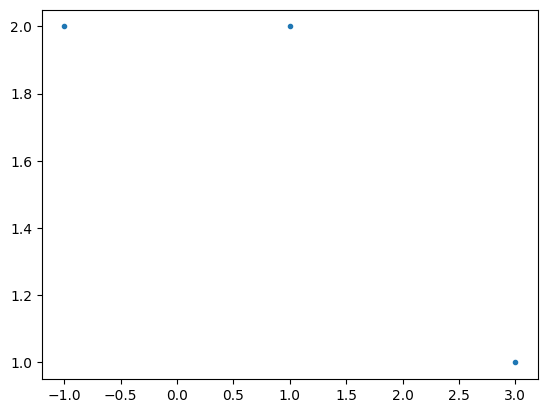

In [ ]:
A

array([[ 1,  2],
       [ 3,  1],
       [-1,  2]])

EJERCICIO: Plotea los datos

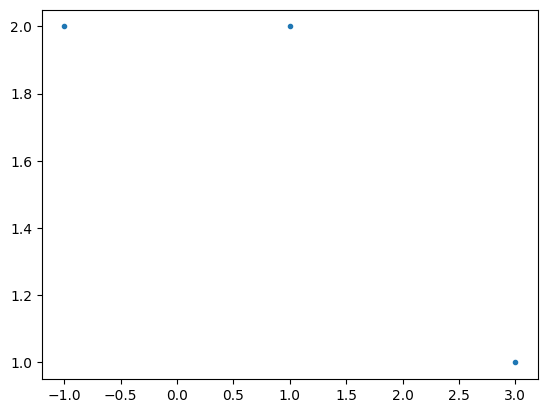

In [ ]:
plt.plot(A[:,0],A[:,1],'.')

In [ ]:
p= 0.1
(2**p + 0**p)**(1/p)

1456.8762338020144

EJERCICIO: Calcula las distancias Lp para p=[0, 0'5, 1, 2, 3, inf]

In [ ]:
for p in [0.00001, 0.5, 1, 2, 3, 10000000]:
    print('p = ' + str(p))

    M = np.zeros((3,3))
    for n in range(A.shape[0]):
        for m in range(A.shape[0]):
            M[m,n] = (np.abs(A[n,0]-A[m,0])**p+np.abs(A[n,1]-A[m,1])**p)**(1/p)

    print(M)

p = 1e-05
[[ 0. inf  2.]
 [inf  0. inf]
 [ 2. inf  0.]]
p = 0.5
[[0.         5.82842712 2.        ]
 [5.82842712 0.         9.        ]
 [2.         9.         0.        ]]
p = 1
[[0. 3. 2.]
 [3. 0. 5.]
 [2. 5. 0.]]
p = 2
[[0.         2.23606798 2.        ]
 [2.23606798 0.         4.12310563]
 [2.         4.12310563 0.        ]]
p = 3
[[0.         2.08008382 2.        ]
 [2.08008382 0.         4.02072576]
 [2.         4.02072576 0.        ]]
p = 10000000
[[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]


<ipython-input-14-611a4381d6d8>:7: RuntimeWarning: overflow encountered in scalar power
  M[m,n] = (np.abs(A[n,0]-A[m,0])**p+np.abs(A[n,1]-A[m,1])**p)**(1/p)


## Muchos datos 1D

In [ ]:
N = 1000

# Valores ejemplo
y = np.random.rand(N,1)

# Valores test
y_hat = y + 0.5*np.random.randn(y.shape[0],y.shape[1])

Text(0, 0.5, 'valores test')

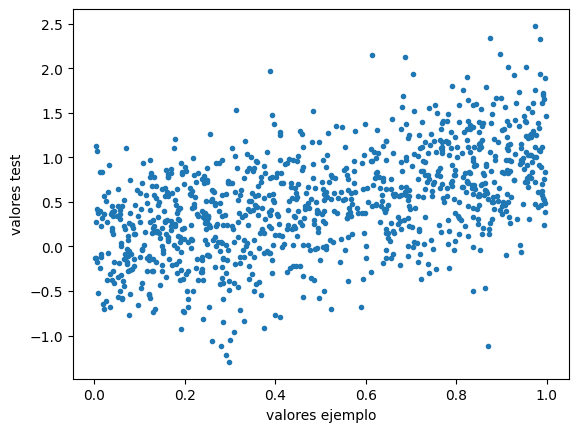

In [ ]:
plt.plot(y,y_hat,'.')
plt.xlabel('valores ejemplo')
plt.ylabel('valores test')

In [ ]:
y.shape

(1000, 1)

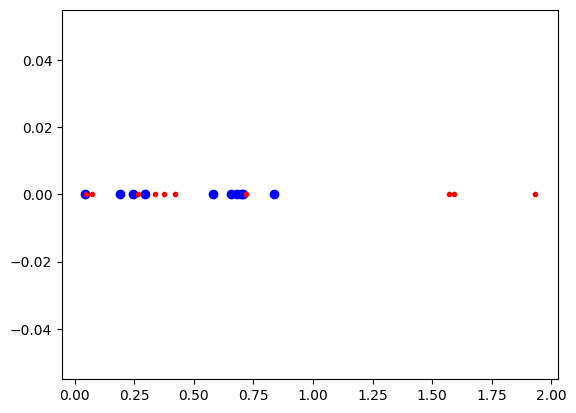

In [ ]:
nn=10
plt.plot(y[0:nn,0],np.zeros((nn,)),'bo')
plt.plot(y_hat[0:nn,0],np.zeros((nn,)),'r.')


EJERCICIO: Calcula las distancias Lp (p=[0, 0'5, 1, 2, 3, inf]) entre los valores reales y los predichos para distintas cantidades de ruido


In [ ]:
p = 1

M = np.zeros((y.shape[0],y.shape[0]))
for n in range(y.shape[0]):
    for m in range(y.shape[0]):
        M[m,n] = (np.abs(y[n,0]-y_hat[m,0])**p)**(1/p)



In [ ]:
mmm = np.min(M,axis=1)

In [ ]:
mmm.shape

(1000,)

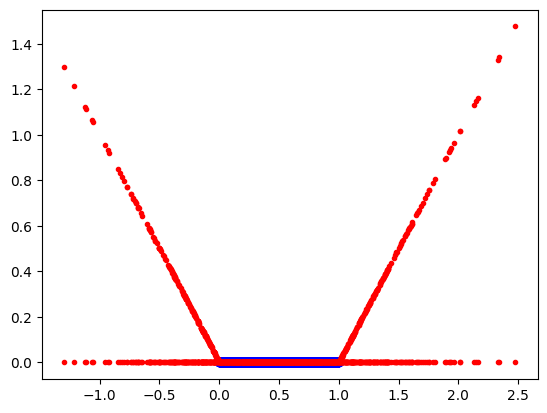

In [ ]:
nn=1000
plt.plot(y[0:nn,0],np.zeros((nn,)),'bo')
plt.plot(y_hat[0:nn,0],mmm[0:nn],'r.')
plt.plot(y_hat[0:nn,0],np.zeros((nn,)),'r.')

EJERCICIO: Mete algún dato anómalo (outlier) y mira como afecta a cada una de las distancias.

## Muchos datos 2D

Text(0, 0.5, 'Y')

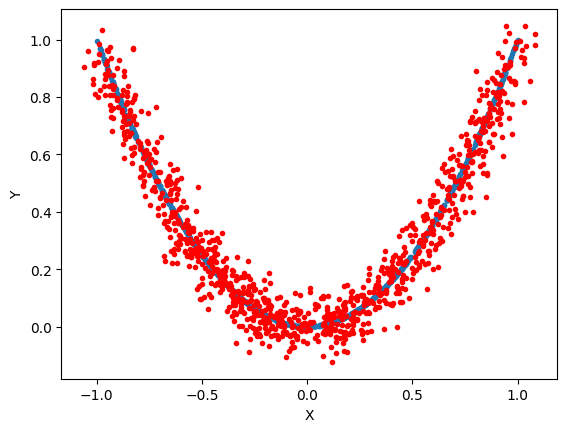

In [ ]:
N = 1000

# Valores ejemplo
x = 2*((np.random.rand(N,1))-0.5)
y = x**2

# Valores test
sigma = 0.05
y_hat = y + sigma*np.random.randn(y.shape[0],y.shape[1])
x_hat = x + sigma*np.random.randn(x.shape[0],x.shape[1])

plt.plot(x,y,'.')
plt.plot(x_hat,y_hat,'r.')
plt.xlabel('X')
plt.ylabel('Y')

EJERCICIO: Calcula las distancias Lp entre cada punto 2D para distintas cantidades de ruido. ¿Que punto tiene las mayores distancias para cada valor de p y de sigma?


In [ ]:
p = 1

M = np.zeros((y.shape[0],y.shape[0]))
for n in range(y.shape[0]):
    for m in range(y.shape[0]):
        M[m,n] = ((np.abs(x[n,0]-x_hat[m,0]))**p+(np.abs(y[n,0]-y_hat[m,0]))**p)**(1/p)

In [ ]:
mmm = np.min(M,axis=1)

EJERCICIO: Busca puntos que se detecten como outlier solo por algunas distancias.

Text(0, 0.5, 'Y')

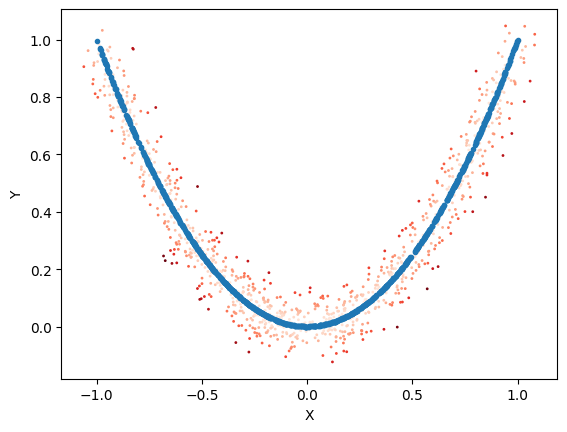

In [ ]:

plt.plot(x,y,'.')
plt.scatter(x_hat,y_hat, s=1, c=mmm, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

EJERCICIO: Dibuja los valores en 2D que distan "1" del centro (0,0) para las distancias Lp (p=[0, 0'5, 1, 2, 3, inf]).


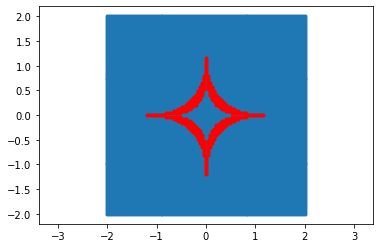

## Datos a partir de una imagen

EJERCICIO: Con la siguiente imagen:

* Conviértela en datos de (D,N) tomando como dato patches de 8x8x3 y convirtiéndolos en vectores, es decir cada dato tiene dimensión D = 192.
* Calcula las distancias Lp entre dos patches.
* Calcula la distancia de mahalanobis entre dos patches.

In [ ]:
import matplotlib.pyplot as plt

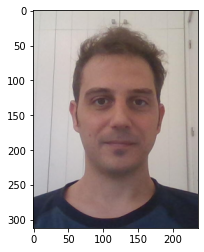

In [ ]:
# Hay muchas opciones para leer imagenes, openCV, PIL, sklearn...
from skimage import io

im = io.imread('https://www.uv.es/lapeva/Valero_2020_DQ.png')

plt.imshow(im)

EJERCICIO: Mete un patch anomalo usando distintas estrategias en la imagen y analiza su distancia a los otros patches. Puedes probar las siguientes anomalias:  

* Pon el patch en negro (todos los valores a 0)
* Escala el valor del patch (multiplícalo por un valor un poco mas grande de 1).
* Cambia el contraste del patch.
* Mete ruido en el patch.